https://github.com/s-gonaboyina/customer-churn-prediction

# Customer Churn Prediction with Logistic Regression
**IN503 Introduction to Machine Learning | Unit 10 Assignment**
Sesha Gonaboyina | Purdue Global University

## Project overview
A telecom company loses revenue every time a customer leaves, and winning a new customer usually costs more than keeping an existing one. The goal here is to predict which customers are likely to churn so a retention team can contact them before they go.

I use the Telco Customer Churn dataset (7,043 customers, 21 columns, target `Churn` = Yes/No). The workflow follows the same order I would use on a real project: explore the data, fix quality problems, build a leakage-safe preprocessing pipeline, tune and train a logistic regression model, evaluate it, read the coefficients as business drivers, and save the full pipeline so it can be reused on new customers.

## Phase 1: Environment setup

In [1]:
!pip install kagglehub -q

In [2]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score,
                             roc_auc_score, RocCurveDisplay)
import joblib
import os

# Set pandas display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## Phase 2: Data acquisition and exploration
### 2.1 Load the dataset
The notebook tries `kagglehub` first. My work network blocks some direct dataset downloads, so if that fails the code falls back to a local copy of `WA_Fn-UseC_-Telco-Customer-Churn.csv` (upload it to the Colab session or place it next to the notebook).

In [3]:
CSV_NAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
try:
    # Download latest version
    path = kagglehub.dataset_download("blastchar/telco-customer-churn")
    filepath = os.path.join(path, CSV_NAME)
except Exception as err:
    print("kagglehub download failed, using local file instead:", type(err).__name__)
    filepath = CSV_NAME
print("Path to dataset files: ", filepath)

# Load the dataset
df = pd.read_csv(filepath)

# Display the first 5 rows
print("First 5 rows of the dataset:")
print(df.head())

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files:  /kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
First 5 rows of the dataset:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes           Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes           No              Yes          No          No              No        One year       

### 2.2 Dataset overview and basic statistics

In [4]:
print("Shape of the dataset: ")
print(df.shape)

print("\nDataFrame Info: ")
df.info()

print("\nDescriptive statistics for numerical features:")
print(df.describe())

print("\nSummary of categorical features:")
print(df.describe(include='object').T[['count', 'unique', 'top', 'freq']])

Shape of the dataset: 
(7043, 21)

DataFrame Info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   obj

**Key findings (overview).** The shape should read 7,043 rows by 21 columns. Only `tenure`, `MonthlyCharges`, and `SeniorCitizen` are stored as numbers by default. `TotalCharges` shows up as `object`, which is a warning sign because a charge amount should be numeric. `SeniorCitizen` is a 0/1 flag, so its mean in `describe()` is just the share of senior customers, not a typical "average" in the usual sense.

### 2.3 Missing value analysis (including the hidden TotalCharges issue)

In [5]:
print("Missing values before handling: ")
print(df.isnull().sum())

# Check for empty strings in TotalCharges (blanks that pandas does not count as null)
total_charges_missing = df[df['TotalCharges'] == ' '].shape[0]
print(f"\nNumber of empty strings in 'TotalCharges': {total_charges_missing}")

# Which customers are they?
print(df.loc[df['TotalCharges'] == ' ', ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']])

Missing values before handling: 
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of empty strings in 'TotalCharges': 11
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
3331  7644-OMVMY       0           19.85             
3826  3213-VVOLG       0           25.35             
4380  2520-SG

`isnull()` reports zero missing values everywhere, but that is misleading. The blank strings in `TotalCharges` are invisible to it and they are what forced the column to `object`. The rows above all have `tenure` = 0, meaning brand-new customers who have not been billed yet, so a missing total is explained by the data itself. With so few rows, dropping them costs almost nothing, and imputing 0 would be a second reasonable choice. I follow the assignment and drop them.

In [6]:
# Replace empty strings with NaN and convert values to float
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan).astype(float)

print("Missing values after handling 'TotalCharges' type: ")
print(df.isnull().sum())

# Drop rows with missing values (small number)
df.dropna(inplace=True)

print("\nMissing values after dropping rows: ")
print(df.isnull().sum())
print(f"New dataset shape: {df.shape}")

Missing values after handling 'TotalCharges' type: 
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after dropping rows: 
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges    

### 2.4 Target variable analysis

Churn distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


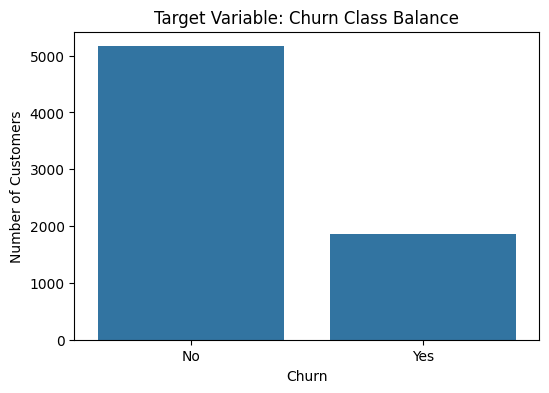

In [7]:
print("Churn distribution:")
print(df['Churn'].value_counts())

churn_percentage = df['Churn'].value_counts(normalize=True) * 100
print("\nChurn percentage:")
print(churn_percentage)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', order=['No', 'Yes'])
plt.title('Target Variable: Churn Class Balance')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

**Class imbalance.** "No" customers outnumber "Yes" customers by roughly 3 to 1 (about 73% vs 27%). That matters for evaluation later: a model that predicts "No Churn" for everyone would already score about 73% accuracy while catching zero churners. Accuracy alone cannot be trusted here, so I also track precision, recall, F1, and AUC for the churn class, and I use a stratified split so both sets keep the same ratio.

### 2.5 Visualizations

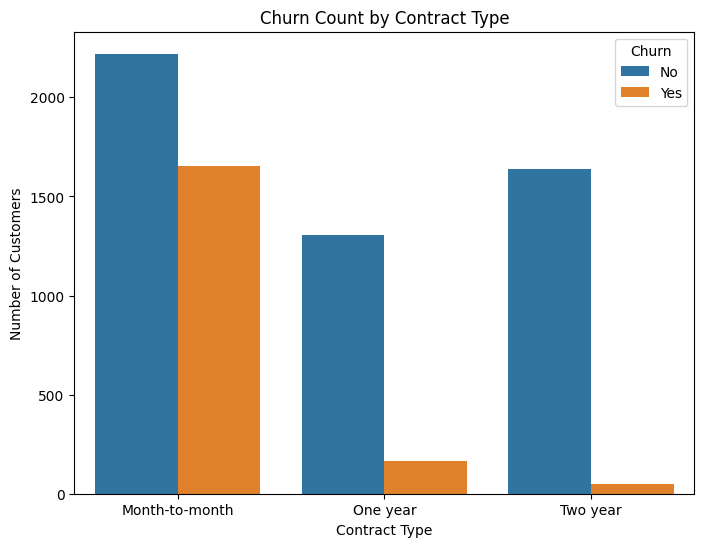

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn rate (%), dtype: float64


In [8]:
# Visualization 1: Churn by Contract Type
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Churn Count by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

print((df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
         .round(1).rename('Churn rate (%)')))

**Insight.** Month-to-month customers churn far more often than one-year or two-year customers. A contract is a commitment device, so contract length is likely one of the strongest levers for retention.

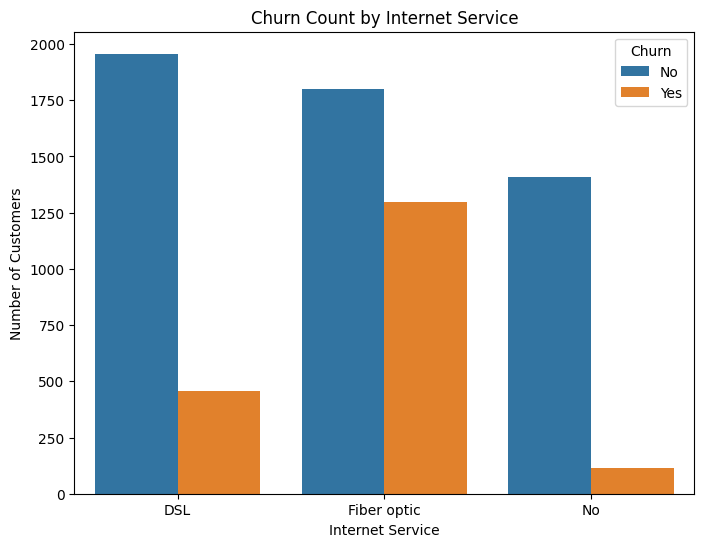

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn rate (%), dtype: float64


In [9]:
# Visualization 2: Churn by Internet Service
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.title('Churn Count by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

print((df.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
         .round(1).rename('Churn rate (%)')))

**Insight.** Fiber optic customers churn at a clearly higher rate than DSL customers or those with no internet service. Fiber is the premium product, so this points to price, service quality, or competing offers, and it is worth a follow-up with the business.

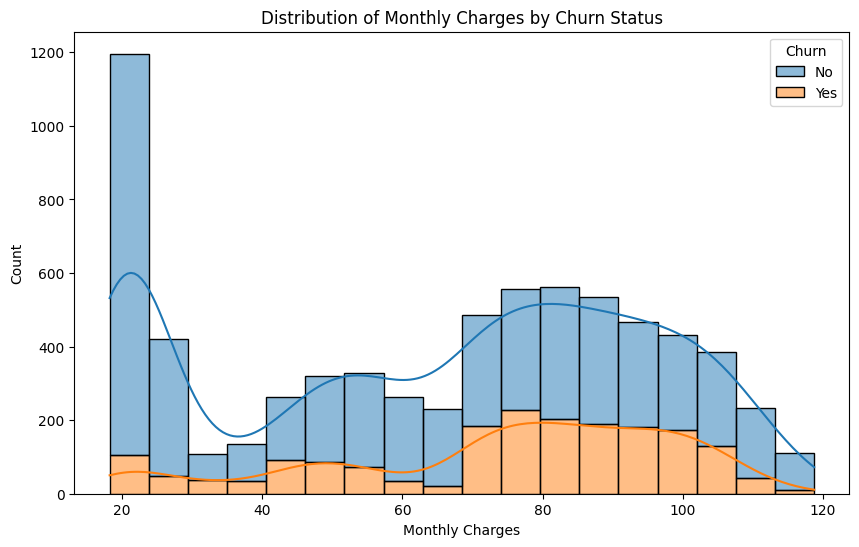

        count   mean    std    min    25%    50%    75%     max
Churn                                                          
No     5163.0  61.31  31.09  18.25  25.10  64.45  88.48  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.65  94.20  118.35


In [10]:
# Visualization 3: Monthly Charges Distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple='stack', kde=True)
plt.title('Distribution of Monthly Charges by Churn Status')
plt.xlabel('Monthly Charges')
plt.ylabel('Count')
plt.show()

print(df.groupby('Churn')['MonthlyCharges'].describe().round(2))

**Insight.** Churners sit more heavily in the higher monthly charge range (the average for churners is above that of retained customers, see table). Customers on cheap plans are mostly retained, so the risk grows as the bill grows.

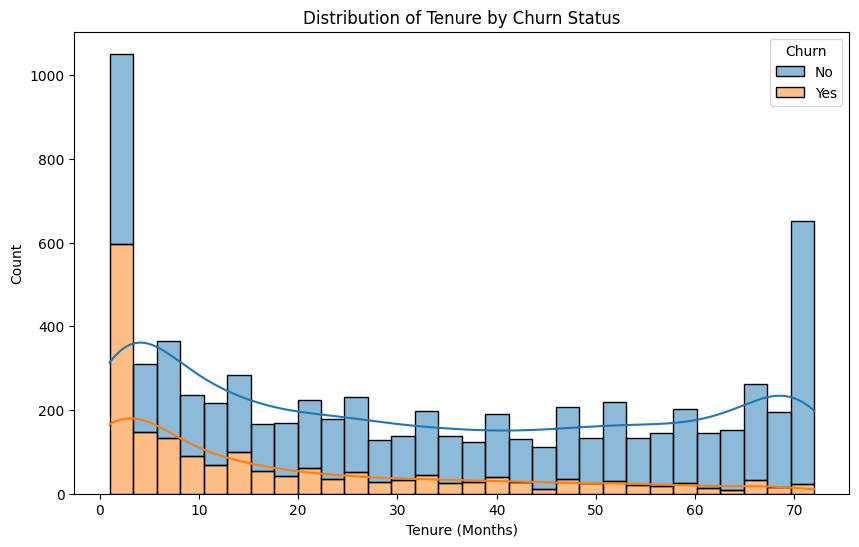

        count  mean   std  min   25%   50%   75%   max
Churn                                                 
No     5163.0  37.7  24.1  1.0  15.0  38.0  61.0  72.0
Yes    1869.0  18.0  19.5  1.0   2.0  10.0  29.0  72.0


In [11]:
# Visualization 4: Tenure Distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='tenure', bins=30, kde=True, hue='Churn', multiple='stack')
plt.title('Distribution of Tenure by Churn Status')
plt.xlabel('Tenure (Months)')
plt.ylabel('Count')
plt.show()

print(df.groupby('Churn')['tenure'].describe().round(1))

**Insight.** Churn is concentrated in the first few months of tenure and falls off steadily after that. The first year is the critical window for onboarding and early retention offers.

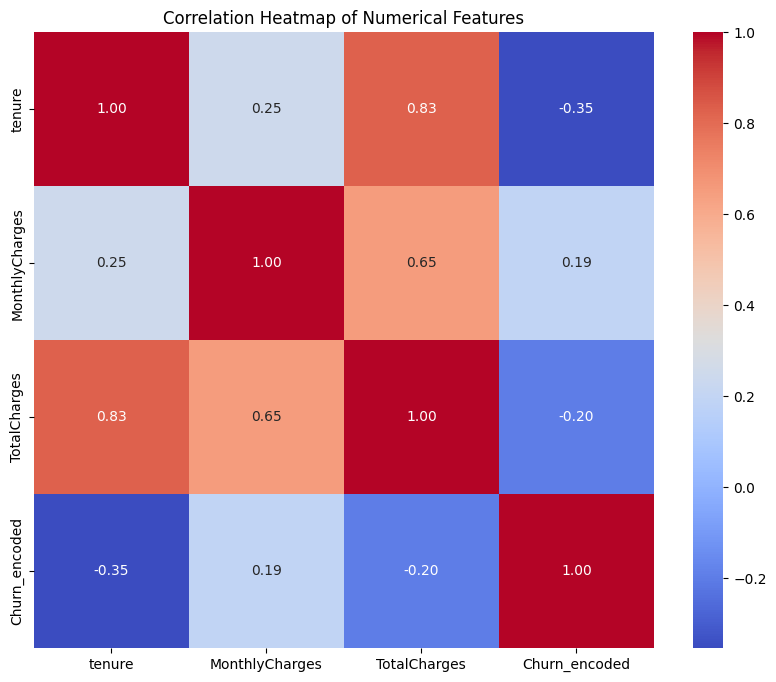

In [12]:
# Visualization 5: Correlation Heatmap
# Create temporary encoded churn variable
df['Churn_encoded'] = df['Churn'].map({'No': 0, 'Yes': 1})
numerical_df = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_encoded']]

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

# Clean up temporary column
df.drop('Churn_encoded', axis=1, inplace=True)

**Insight.** `tenure` has a negative correlation with churn (longer tenure, less churn), `MonthlyCharges` has a weak positive one. `TotalCharges` is strongly correlated with `tenure` because it is roughly tenure multiplied by the monthly rate. Features that overlap this much make individual coefficients less stable in a linear model, so I keep that in mind when reading coefficients later.

## Phase 3: Data preprocessing and feature engineering
### 3.1 Prepare features and target
The `customerID` column is only an identifier and carries no signal, so I drop it.

In [13]:
# Drop customerID as it's just an identifier
df.drop('customerID', axis=1, inplace=True)

### 3.2 Feature engineering: `total_services`
I create one new feature, `total_services`, the number of services a customer subscribes to (phone, internet, and the six add-ons: security, backup, device protection, tech support, streaming TV, streaming movies). The idea is that customers with more services are more tied into the company and may be less likely to leave. It is calculated row by row from that customer's own values, so computing it before the train/test split does not leak any information between the sets.

In [14]:
ADDON_COLS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_total_services(data):
    """Return a copy of data with a total_services column (0 to 8)."""
    data = data.copy()
    count = (data['PhoneService'] == 'Yes').astype(int)
    count += (data['InternetService'] != 'No').astype(int)
    for col in ADDON_COLS:
        count += (data[col] == 'Yes').astype(int)
    data['total_services'] = count
    return data

df = add_total_services(df)
print(df[['PhoneService', 'InternetService'] + ADDON_COLS + ['total_services']].head())

print((df.groupby('total_services')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
         .round(1).rename('Churn rate (%)')))

  PhoneService InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies  total_services
0           No             DSL             No          Yes               No          No          No              No               2
1          Yes             DSL            Yes           No              Yes          No          No              No               4
2          Yes             DSL            Yes          Yes               No          No          No              No               4
3           No             DSL            Yes           No              Yes         Yes          No              No               4
4          Yes     Fiber optic             No           No               No          No          No              No               2
total_services
1     9.2
2    51.6
3    43.5
4    34.7
5    27.3
6    22.1
7    12.6
8     5.8
Name: Churn rate (%), dtype: float64


### 3.3 Separate features and target, then identify column types

In [15]:
# Define features (X) and target (y)
X = df.drop('Churn', axis=1)
y = df['Churn']

# Convert target to numerical format
y = y.map({'No': 0, 'Yes': 1})

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=np.number).columns
print(f"Categorical columns ({len(categorical_cols)}): {list(categorical_cols)}")
print(f"Numerical columns ({len(numerical_cols)}): {list(numerical_cols)}")

Categorical columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns (5): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'total_services']


### 3.4 Preprocessing pipeline
Numerical columns go through `StandardScaler` and categorical columns through `OneHotEncoder(handle_unknown='ignore')`, combined with a `ColumnTransformer`. Because this lives inside the final `Pipeline`, scaling statistics and category lists are learned from the training data only. That prevents data leakage, including inside each cross-validation fold of the grid search. `handle_unknown='ignore'` keeps the saved model from crashing if a new customer has a category it never saw.

In [16]:
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

## Phase 4: Model building and training
### 4.1 Train/test split
80/20 split with `stratify=y` so the churn share is the same in both sets, and `random_state=42` for reproducibility.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} rows")
print(f"Testing set size: {X_test.shape[0]} rows")
print("\nChurn share, train vs test:")
print(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                    'test': y_test.value_counts(normalize=True)}).round(4))

Training set size: 5625 rows
Testing set size: 1407 rows

Churn share, train vs test:
        train    test
Churn                
0      0.7342  0.7342
1      0.2658  0.2658


### 4.2 Why logistic regression suits this problem
- **Binary target.** Churn is Yes/No, and logistic regression outputs a probability between 0 and 1 for the positive class, which can be turned into a decision with a threshold.
- **Interpretable.** Each coefficient is the change in log-odds of churn for a one-unit change in a feature (holding the others fixed), and `exp(coefficient)` gives an odds ratio. A retention manager can act on "month-to-month contracts raise the odds of churning" far more easily than on a black-box score.
- **Works well with one-hot and scaled inputs.** Once features are encoded and scaled, the model trains quickly and the coefficients are comparable in size.
- **Probabilities are useful.** Ranking customers by churn probability lets the business spend its retention budget on the riskiest accounts first.
- **Regularization is built in.** The parameter `C` controls how strongly large coefficients are penalized, which helps with the overlapping features seen in the heatmap (`tenure`, `TotalCharges`).

Limits: it assumes a linear relationship between features and log-odds, so interactions (for example, fiber and short tenure together) are not captured unless they are engineered.

### 4.3 Hyperparameter tuning of C with GridSearchCV
`C` is the inverse of regularization strength (smaller C means stronger regularization). I search a log-spaced grid with 5-fold stratified cross-validation on the training set only, scoring on ROC AUC because it does not depend on a threshold and is less misleading than accuracy under class imbalance.

In [18]:
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear', random_state=42))
])

param_grid = {'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(model_pipeline, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)

print("Tuning C and training the logistic regression pipeline... ")
grid.fit(X_train, y_train)

print("Best C:", grid.best_params_['classifier__C'])
print(f"Best cross-validated AUC: {grid.best_score_:.4f}")
print(pd.DataFrame(grid.cv_results_)[['param_classifier__C', 'mean_test_score', 'std_test_score']].round(4))

# The best pipeline is refit on the full training set, and it is the final model
final_model = grid.best_estimator_
print("\nModel training complete.")

Tuning C and training the logistic regression pipeline... 
Best C: 100
Best cross-validated AUC: 0.8462
   param_classifier__C  mean_test_score  std_test_score
0                0.001           0.8386          0.0182
1                0.010           0.8429          0.0194
2                0.100           0.8450          0.0194
3                1.000           0.8459          0.0189
4               10.000           0.8462          0.0190
5              100.000           0.8462          0.0190

Model training complete.


## Phase 5: Model evaluation and interpretation
### 5.1 Metrics on the test set

In [19]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
baseline = (y_test == 0).mean()

print("Model Evaluation on Test Data:")
print(f"Accuracy : {accuracy:.4f}  (always-predict-No baseline: {baseline:.4f})")
print(f"Precision: {precision:.4f}  (churn class)")
print(f"Recall   : {recall:.4f}  (churn class)")
print(f"F1-score : {f1:.4f}  (churn class)")
print(f"ROC AUC  : {auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))

Model Evaluation on Test Data:
Accuracy : 0.7967  (always-predict-No baseline: 0.7342)
Precision: 0.6317  (churn class)
Recall   : 0.5642  (churn class)
F1-score : 0.5960  (churn class)
ROC AUC  : 0.8348

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.88      0.86      1033
       Churn       0.63      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.74      0.72      0.73      1407
weighted avg       0.79      0.80      0.79      1407



Confusion Matrix:
[[910 123]
 [163 211]]


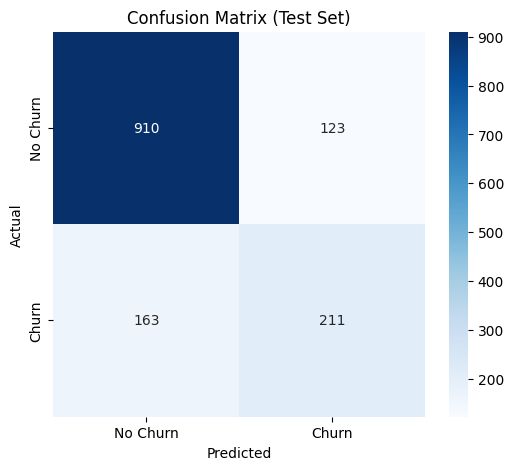

True negatives: 910 | False positives: 123 | False negatives: 163 | True positives: 211


In [20]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

tn, fp, fn, tp = conf_matrix.ravel()
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}")

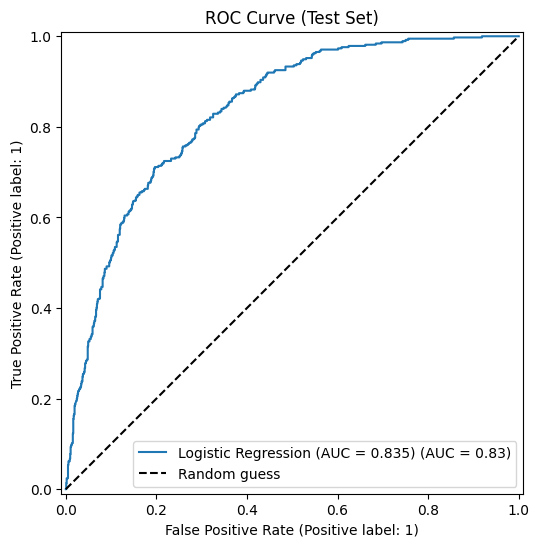

In [21]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, y_proba, name=f'Logistic Regression (AUC = {auc:.3f})', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_title('ROC Curve (Test Set)')
ax.legend(loc='lower right')
plt.show()

### Reading the metrics in business terms
- **Accuracy** is the share of all customers classified correctly. Because about 73% of customers do not churn, it must be compared with the always-"No" baseline printed above. The model beats that baseline, but the gain is modest, so accuracy alone is not the story.
- **Precision (churn)** answers: of the customers the model flags, how many really leave? Low precision means retention offers go to customers who would have stayed anyway, which wastes discount budget.
- **Recall (churn)** answers: of the customers who really leave, how many did the model catch? This is usually the weaker number because of the class imbalance. Each missed churner (false negative) is lost revenue with no chance to intervene.
- **F1** balances precision and recall in one number for the churn class.
- **AUC** measures how well the model ranks churners above non-churners across all thresholds. It shows the model has useful ranking power even where the default 0.5 threshold gives mediocre recall.

**Imbalance.** The default 0.5 cutoff favors the majority class, so recall for churners trails recall for non-churners. Since a missed churner usually costs more than a wasted offer, a real deployment should lower the threshold (or use `class_weight='balanced'`) and pick it based on the cost of an offer versus the value of a retained customer. I kept the default threshold here to match the assignment, and `predict_churn()` below exposes the threshold as a parameter.

### 5.2 Interpreting the coefficients

Top 10 most impactful features on Churn:
                             Feature  Coefficient  Odds_Ratio  Abs_Coefficient
                      MonthlyCharges      -2.2764      0.1027           2.2764
                              tenure      -1.4117      0.2437           1.4117
         InternetService_Fiber optic       1.3430      3.8306           1.3430
                 InternetService_DSL      -1.2939      0.2742           1.2939
                      total_services       0.8500      2.3397           0.8500
                   Contract_Two year      -0.8350      0.4339           0.8350
                        TotalCharges       0.7053      2.0245           0.7053
             Contract_Month-to-month       0.5800      1.7860           0.5800
     TechSupport_No internet service      -0.4861      0.6150           0.4861
DeviceProtection_No internet service      -0.4861      0.6150           0.4861


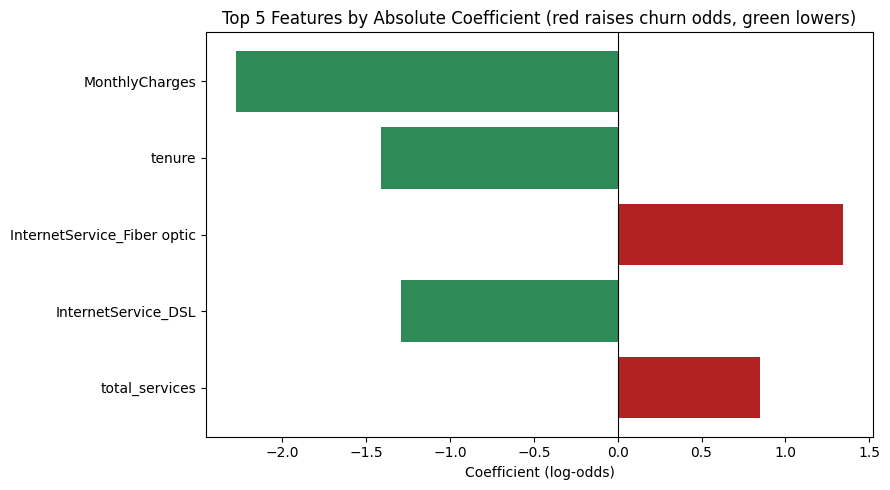

In [22]:
# Extract trained components
log_reg = final_model.named_steps['classifier']
fitted_pre = final_model.named_steps['preprocessor']

# Get feature names after one-hot encoding
ohe_feature_names = fitted_pre.named_transformers_['cat'].get_feature_names_out(categorical_cols)
feature_names = list(numerical_cols) + list(ohe_feature_names)

coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': log_reg.coef_[0]
})
coefficients['Odds_Ratio'] = np.exp(coefficients['Coefficient'])
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients.sort_values(by='Abs_Coefficient', ascending=False, inplace=True)

print("Top 10 most impactful features on Churn:")
print(coefficients.head(10).round(4).to_string(index=False))

top5 = coefficients.head(5).iloc[::-1]
plt.figure(figsize=(9, 5))
colors = ['firebrick' if c > 0 else 'seagreen' for c in top5['Coefficient']]
plt.barh(top5['Feature'], top5['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 5 Features by Absolute Coefficient (red raises churn odds, green lowers)')
plt.xlabel('Coefficient (log-odds)')
plt.tight_layout()
plt.show()

In [23]:
# Plain-language translation of the top five coefficients
numeric_set = set(numerical_cols)
print("Top five drivers, in business terms:\n")
for _, row in coefficients.head(5).iterrows():
    direction = "raises" if row['Coefficient'] > 0 else "lowers"
    if row['Feature'] in numeric_set:
        unit = "a one standard deviation increase in"
    else:
        unit = "being in the group"
    print(f"- {row['Feature']}: {unit} this feature {direction} the odds of churn "
          f"by a factor of {row['Odds_Ratio']:.2f} (coefficient {row['Coefficient']:+.2f}), "
          f"holding other features constant.")

Top five drivers, in business terms:

- MonthlyCharges: a one standard deviation increase in this feature lowers the odds of churn by a factor of 0.10 (coefficient -2.28), holding other features constant.
- tenure: a one standard deviation increase in this feature lowers the odds of churn by a factor of 0.24 (coefficient -1.41), holding other features constant.
- InternetService_Fiber optic: being in the group this feature raises the odds of churn by a factor of 3.83 (coefficient +1.34), holding other features constant.
- InternetService_DSL: being in the group this feature lowers the odds of churn by a factor of 0.27 (coefficient -1.29), holding other features constant.
- total_services: a one standard deviation increase in this feature raises the odds of churn by a factor of 2.34 (coefficient +0.85), holding other features constant.


**How to read these.** A positive coefficient raises the log-odds of churn and a negative one lowers it. Exponentiating gives an odds ratio: 1.0 means no effect, above 1 means higher churn odds, below 1 means lower. For one-hot features such as `Contract_Two year`, the effect is relative to the other contract types. Numeric features were standardized, so their coefficients describe a one standard deviation change.

**Caution.** `tenure`, `MonthlyCharges`, `TotalCharges`, and the internet service and service-count features overlap with each other (see the heatmap), so a single coefficient can look larger or flip sign compared with its raw correlation. These coefficients show association inside this model, not proven cause and effect. The churn drivers I rely on for recommendations are the ones that also showed up clearly in the visualizations: contract type, internet service type, tenure, and monthly charges.

## Phase 6: Model deployment simulation
### 6.1 Save the full pipeline
Saving the whole pipeline (not just the classifier) means the scaler and encoder travel with the model, so new data goes through exactly the same preprocessing.

In [24]:
model_filename = 'customer_churn_model.pkl'
joblib.dump(final_model, model_filename)
print(f"Trained model pipeline saved as '{model_filename}'")

Trained model pipeline saved as 'customer_churn_model.pkl'


### 6.2 Load the model and build a prediction function

In [25]:
loaded_model = joblib.load('customer_churn_model.pkl')
print("Model pipeline loaded successfully.")

REQUIRED_FIELDS = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
                   'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                   'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
                   'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
                   'MonthlyCharges', 'TotalCharges']

def predict_churn(customer, model=loaded_model, threshold=0.5):
    """Predict churn for one customer (dict) or several (DataFrame).

    Returns a DataFrame with churn probability and a Yes/No prediction.
    Lower the threshold to catch more churners at the cost of more false alarms.
    """
    data = pd.DataFrame(customer) if not isinstance(customer, pd.DataFrame) else customer.copy()
    missing = [c for c in REQUIRED_FIELDS if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required fields: {missing}")
    data = add_total_services(data[REQUIRED_FIELDS])   # same feature engineering as training
    proba = model.predict_proba(data)[:, 1]
    return pd.DataFrame({'churn_probability': proba.round(3),
                         'predicted_churn': np.where(proba >= threshold, 'Yes', 'No')})

Model pipeline loaded successfully.


### 6.3 Example predictions

In [26]:
# Customer A: new, month-to-month, fiber, no add-ons, electronic check (several risk factors)
customer_a = {
    'gender': ['Male'], 'SeniorCitizen': [0], 'Partner': ['No'], 'Dependents': ['No'],
    'tenure': [1], 'PhoneService': ['Yes'], 'MultipleLines': ['No'],
    'InternetService': ['Fiber optic'], 'OnlineSecurity': ['No'], 'OnlineBackup': ['No'],
    'DeviceProtection': ['No'], 'TechSupport': ['No'], 'StreamingTV': ['No'],
    'StreamingMovies': ['No'], 'Contract': ['Month-to-month'], 'PaperlessBilling': ['Yes'],
    'PaymentMethod': ['Electronic check'], 'MonthlyCharges': [75.75], 'TotalCharges': [75.75]
}

# Customer B: long tenure, two-year contract, DSL with protection add-ons (low risk)
customer_b = {
    'gender': ['Female'], 'SeniorCitizen': [0], 'Partner': ['Yes'], 'Dependents': ['Yes'],
    'tenure': [60], 'PhoneService': ['Yes'], 'MultipleLines': ['Yes'],
    'InternetService': ['DSL'], 'OnlineSecurity': ['Yes'], 'OnlineBackup': ['Yes'],
    'DeviceProtection': ['Yes'], 'TechSupport': ['Yes'], 'StreamingTV': ['No'],
    'StreamingMovies': ['No'], 'Contract': ['Two year'], 'PaperlessBilling': ['No'],
    'PaymentMethod': ['Bank transfer (automatic)'], 'MonthlyCharges': [70.0], 'TotalCharges': [4200.0]
}

# Customer C: mid tenure, one-year contract, fiber (a middle case)
customer_c = {
    'gender': ['Female'], 'SeniorCitizen': [1], 'Partner': ['No'], 'Dependents': ['No'],
    'tenure': [14], 'PhoneService': ['Yes'], 'MultipleLines': ['No'],
    'InternetService': ['Fiber optic'], 'OnlineSecurity': ['No'], 'OnlineBackup': ['Yes'],
    'DeviceProtection': ['No'], 'TechSupport': ['No'], 'StreamingTV': ['Yes'],
    'StreamingMovies': ['Yes'], 'Contract': ['One year'], 'PaperlessBilling': ['Yes'],
    'PaymentMethod': ['Credit card (automatic)'], 'MonthlyCharges': [95.0], 'TotalCharges': [1330.0]
}

for name, cust in [('A (new, month-to-month, fiber)', customer_a),
                   ('B (long tenure, two-year, DSL)', customer_b),
                   ('C (mid tenure, one-year, fiber)', customer_c)]:
    result = predict_churn(cust)
    print(f"Customer {name}: P(churn) = {result.loc[0, 'churn_probability']:.3f} -> "
          f"Predicted Churn: {result.loc[0, 'predicted_churn']}")

Customer A (new, month-to-month, fiber): P(churn) = 0.597 -> Predicted Churn: Yes
Customer B (long tenure, two-year, DSL): P(churn) = 0.006 -> Predicted Churn: No
Customer C (mid tenure, one-year, fiber): P(churn) = 0.448 -> Predicted Churn: No


### 6.4 How this could be deployed in a real application
1. **Wrap it in an API.** Load `customer_churn_model.pkl` once at startup inside a FastAPI service. A `/predict` endpoint takes customer JSON, validates the fields with a Pydantic model (the same fields as `REQUIRED_FIELDS`), calls `predict_churn()`, and returns the probability and label.
2. **Containerize.** Package the service in a Docker image with pinned library versions (the pickle must be loaded with the same scikit-learn version that saved it), then run it on a managed platform such as AWS SageMaker or Azure ML, or on a container service.
3. **Connect it to the business process.** Run a nightly batch job that scores all active customers and pushes the highest-risk accounts into the CRM so the retention team can act. Real-time scoring can sit behind a call-center screen.
4. **Monitor and retrain.** Track the share of predicted churners, the data distribution of incoming features, and actual churn outcomes. If the data drifts or performance drops, retrain on fresh data and version the model file.
5. **Handle the threshold and the people side.** Set the cutoff from offer cost versus customer value, and keep customer data protected under the company's privacy rules.

## Conclusions and recommendations
**Key findings**
- **Contract type:** Month-to-month customers churn much more than one-year or two-year customers.
- **Service type:** Fiber optic customers churn more than DSL or no-internet customers.
- **Tenure:** New customers are the highest risk, and churn drops as tenure grows.
- **Pricing:** Higher monthly charges go along with higher churn.
- **Model:** The accuracy, precision, recall, F1, and AUC from this run are printed in section 5.1. Accuracy should land near 80% (above the always-"No" baseline), with weaker recall on the minority churn class, which is the main weakness to address through threshold tuning.

**Recommendations**
1. Offer incentives (discount, bill credit, or perks) to move month-to-month customers to longer contracts, especially during the first year.
2. Build an onboarding and check-in program for the first 3 to 6 months, when churn risk is highest.
3. Review fiber pricing and service quality with the product and network teams, since this segment shows elevated churn.
4. Promote add-on services (security, tech support), since customers with more services have more reasons to stay.
5. Use the churn probability to rank accounts and lower the decision threshold so the retention team catches more of the real churners, accepting more false alarms.

**Limitations and next steps.** The data is a single snapshot with no cost or revenue values per customer. Next steps would be comparing against tree-based models, testing `class_weight='balanced'`, and choosing a threshold using actual offer cost and customer lifetime value.

## Reference
Blastchar. (n.d.). *Telco customer churn* [Data set]. Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.